# 05. Línea base clásica: regresión logística y XGBoost

Vamos a entrenar y comparar dos alternativas sencillas sobre las variables del conjunto preparado:

- **Regresión logística:** combina las variables para estimar probabilidades; servirá como referencia inicial.
- **XGBoost:** combina árboles de decisión y puede representar relaciones que no sean lineales.

Cada alternativa tendrá un modelo **binario** y otro **multiclase**. Se ajustan únicamente con entrenamiento y se evalúan en validación. **No se abre `prueba.csv`.**

Reportaremos PR-AUC, ROC-AUC, recall con precisión de al menos 0.80 y matrices de confusión multiclase. Las semillas y los parámetros quedan fijados antes de ver los resultados. Esta es una primera comparación, sin búsqueda de hiperparámetros.

## 1. Preparar las herramientas

Importaremos XGBoost antes que las otras herramientas de modelado para mantener el orden de carga que funciona en el entorno local. Las tablas, figuras, parámetros y explicaciones quedan dentro de este notebook, sin exportar archivos adicionales.

In [1]:
from pathlib import Path
import time
import warnings
import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
    precision_score, recall_score, f1_score, confusion_matrix, classification_report,
)
from threadpoolctl import threadpool_limits

# Localizar las carpetas desde la raíz del proyecto o desde Modelación.
actual = Path.cwd()
if (actual / "Datos").is_dir():
    ruta_repo = actual
elif (actual.parent / "Datos").is_dir():
    ruta_repo = actual.parent
else:
    raise FileNotFoundError("No se encontró la carpeta Datos.")

ruta_datos = ruta_repo / "Datos" / "Datos_preparados"

# Fijar la semilla y limitar los hilos para que el notebook pueda correrse localmente.
SEMILLA = 42
HILOS = 4
np.random.seed(SEMILLA)
nombres_clases = ["ninguno", "comp1", "comp2", "comp3", "comp4"]
mapa_clases = {clase: numero for numero, clase in enumerate(nombres_clases)}
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 25)

## 2. Cargar entrenamiento y validación; revisar los faltantes

Usamos los conjuntos preparados por el notebook 04 o por `preparar_datos.py`. La revisión de valores vacíos se hace antes de transformar las entradas.

Los promedios y desviaciones iniciales pueden estar vacíos porque todavía no hay 3 o 24 horas completas. Esto no significa cero. Si faltara un tiempo desde reemplazo por no existir historia previa, también necesitaría tratamiento.

In [2]:
# Abrir solo estos dos archivos: prueba queda fuera de este notebook.
entrenamiento = pd.read_csv(ruta_datos / "entrenamiento.csv", parse_dates=["datetime"])
validacion = pd.read_csv(ruta_datos / "validación.csv", parse_dates=["datetime"])

# Confirmar las particiones y la coherencia de sus respuestas.
for tabla, inicio, limite in [
    (entrenamiento, pd.Timestamp("2015-01-01"), pd.Timestamp("2015-09-01")),
    (validacion, pd.Timestamp("2015-09-01"), pd.Timestamp("2015-11-01")),
]:
    assert tabla["datetime"].between(inicio, limite, inclusive="left").all()
    assert (tabla["datetime"] + pd.Timedelta(hours=24) < limite).all()
    assert not tabla.duplicated(["machineID", "datetime"]).any()
    assert tabla[["etiqueta_binaria", "etiqueta_multiclase"]].notna().all().all()
    assert (tabla["etiqueta_binaria"] == (tabla["etiqueta_multiclase"] != "ninguno").astype(int)).all()
    assert set(tabla["etiqueta_multiclase"]).issubset(nombres_clases)

faltantes = pd.DataFrame({"entrenamiento": entrenamiento.isna().sum(),
                          "validación": validacion.isna().sum()})
display(faltantes.loc[(faltantes > 0).any(axis=1)])
display(pd.DataFrame({"conjunto": ["entrenamiento", "validación"],
                      "filas": [len(entrenamiento), len(validacion)],
                      "positivos": [int(entrenamiento["etiqueta_binaria"].sum()), int(validacion["etiqueta_binaria"].sum())]}))

,entrenamiento,validación
volt_media_3h,200,0
volt_desv_3h,200,0
rotate_media_3h,200,0
rotate_desv_3h,200,0
pressure_media_3h,200,0
pressure_desv_3h,200,0
vibration_media_3h,200,0
vibration_desv_3h,200,0
volt_media_24h,2300,0
volt_desv_24h,2300,0


,conjunto,filas,positivos
0,entrenamiento,580200,11742
1,validación,144000,2652


Hay faltantes en **16 columnas numéricas de entrenamiento**: 200 en cada variable de 3 horas y 2,300 en cada variable de 24 horas. Validación no tiene faltantes con los archivos actuales.

**¿Se tratan en el pipeline de datos o aquí?** Aquí, dentro del pipeline de modelado. La preparación de datos conserva la ausencia real de historia; el modelo aprenderá una mediana por columna exclusivamente con entrenamiento. Después usará esas mismas medianas al transformar validación y, cuando corresponda, prueba. No calcularemos medianas por separado en cada conjunto ni cambiaremos los CSV originales.

### ¿Esto cambia en las siguientes entregas?

Los faltantes actuales se deben a que todavía no existen suficientes horas para calcular las variables móviles de la línea base; no son huecos en los sensores originales. Por eso conservamos esa ausencia en el paso 04 y aprendemos aquí una solución para los modelos clásicos.

Los modelos secuenciales usarán otra forma de entrada: ventanas de 24, 72 y 168 horas con sensores, errores horarios y tiempo desde reemplazos. No necesitan utilizar estos promedios móviles como canales. Al construir sus ventanas exigiremos la historia necesaria: una hora sin 168 horas previas no tiene todavía una ventana completa de esa longitud. La historia horaria se organizará antes de retirar las horas excluidas por las fronteras de las etiquetas, para no crear huecos artificiales al concatenar los CSV separados.

Si esos canales tuvieran faltantes reales, definiremos su tratamiento en la preparación compartida de las secuencias: por ejemplo, una imputación ajustada solo con entrenamiento, conservando el orden temporal. No rellenaremos con eventos futuros ni aprenderemos estadísticas en validación o prueba. La normalización también se ajustará exclusivamente con entrenamiento.

**No hace falta corregir ahora el paso 04 para rellenarlo todo.** El paso 04 conserva datos y variables históricas; cada preparación de modelado aplica el tratamiento que corresponde a sus entradas. Lo que se aprenda con entrenamiento se conserva sin reajustarlo al evaluar después. En la entrega 3, el modelo elegido mantendrá ese mismo tratamiento; si la arquitectura avanzada requiere otro, se definirá y seleccionará usando entrenamiento y validación, nunca prueba.

## 3. Separar entradas y respuestas

Las 31 variables son las entradas. `machineID` y `datetime` identifican la fila; se excluyen del ajuste, junto con las dos etiquetas.

La tarea binaria usa 0 y 1. Para XGBoost, convertimos la multiclase a números con un mapa fijo: ninguno = 0, comp1 = 1, comp2 = 2, comp3 = 3 y comp4 = 4. Estos números son categorías, no niveles de gravedad.

In [3]:
excluir = ["machineID", "datetime", "etiqueta_binaria", "etiqueta_multiclase"]
columnas_entrada = [columna for columna in entrenamiento.columns if columna not in excluir]
columnas_numericas = [columna for columna in columnas_entrada if columna != "model"]
columnas_categoricas = ["model"]

# Aplicar exactamente las mismas columnas y orden en ambos conjuntos.
X_train = entrenamiento[columnas_entrada].copy()
X_val = validacion[columnas_entrada].copy()
y_train_bin = entrenamiento["etiqueta_binaria"].astype(int)
y_val_bin = validacion["etiqueta_binaria"].astype(int)
y_train_multi = entrenamiento["etiqueta_multiclase"].map(mapa_clases).astype(int)
y_val_multi = validacion["etiqueta_multiclase"].map(mapa_clases).astype(int)

assert len(columnas_entrada) == 31
assert X_train[columnas_numericas].notna().any().all()
assert not np.isinf(X_train[columnas_numericas].to_numpy()).any()
assert not np.isinf(X_val[columnas_numericas].to_numpy()).any()
print("Variables numéricas:", len(columnas_numericas))
print("Variable categórica:", columnas_categoricas)
display(pd.DataFrame({"clase": nombres_clases, "código": range(5)}))

Variables numéricas: 30
Variable categórica: ['model']


,clase,código
0,ninguno,0
1,comp1,1
2,comp2,2
3,comp3,3
4,comp4,4


## 4. Definir las transformaciones y los modelos

El **pipeline de modelado** es distinto del pipeline de preparación del notebook 04: este aprende transformaciones y un clasificador. Sus pasos se ajustan juntos con `.fit()` sobre entrenamiento.

- Numéricas: sustituir vacíos por la mediana de entrenamiento. Para regresión logística, además estandarizar para que las escalas distintas no dominen el ajuste.
- `model`: sustituir vacíos por la categoría más frecuente de entrenamiento y convertir sus categorías en columnas indicadoras (one-hot). Una categoría desconocida después se maneja sin volver a ajustar el codificador.
- Desbalance: dar más peso a las clases menos frecuentes, calculado solo con entrenamiento. En regresión logística se usa `class_weight="balanced"`; en XGBoost binario se ponderan los positivos con la razón negativos/positivos, y en multiclase se ponderan las filas por frecuencia de clase.

Los pesos ayudan a que el modelo atienda a las fallas, pero pueden afectar la calibración de probabilidades. No supondremos que el umbral 0.50 es el mejor ni que las probabilidades ya están calibradas.

Usaremos 150 árboles de profundidad máxima 4 para XGBoost, tasa de aprendizaje 0.05 y semilla 42. No ajustaremos esos parámetros mirando los resultados de esta ejecución.

In [4]:
def crear_transformador(escalar):
    """Aprender la imputación y la codificación solo al ajustar con entrenamiento."""
    pasos_numericos = [("imputar", SimpleImputer(strategy="median"))]

    # La regresión logística necesita escalas comparables; los árboles no lo requieren.
    if escalar:
        pasos_numericos.append(("escalar", StandardScaler()))

    numericas = Pipeline(pasos_numericos)
    categoricas = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numericas", numericas, columnas_numericas),
        ("categoricas", categoricas, columnas_categoricas),
    ])


# Obtener los pesos a partir de las etiquetas de entrenamiento, sin consultar validación.
negativos = int((y_train_bin == 0).sum())
positivos = int((y_train_bin == 1).sum())
peso_positivo = negativos / positivos
pesos_multiclase = compute_sample_weight(class_weight="balanced", y=y_train_multi)

parametros_xgb = dict(n_estimators=150, max_depth=4, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                      n_jobs=HILOS, random_state=SEMILLA)
modelos_binarios = {
    "Regresión logística": Pipeline([
        ("preparar", crear_transformador(escalar=True)),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000, solver="lbfgs", random_state=SEMILLA)),
    ]),
    "XGBoost": Pipeline([
        ("preparar", crear_transformador(escalar=False)),
        ("modelo", xgb.XGBClassifier(**parametros_xgb, objective="binary:logistic",
                                      eval_metric="logloss", scale_pos_weight=peso_positivo)),
    ]),
}
modelos_multiclase = {
    "Regresión logística": Pipeline([
        ("preparar", crear_transformador(escalar=True)),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000, solver="lbfgs", random_state=SEMILLA)),
    ]),
    "XGBoost": Pipeline([
        ("preparar", crear_transformador(escalar=False)),
        ("modelo", xgb.XGBClassifier(**parametros_xgb, objective="multi:softprob", num_class=5, eval_metric="mlogloss")),
    ]),
}
print("Razón negativos/positivos en entrenamiento:", round(peso_positivo, 3))

Razón negativos/positivos en entrenamiento: 48.412


## 5. Entrenar y obtener probabilidades en validación

`.fit()` aprende de entrenamiento. `.predict_proba()` utiliza lo ya aprendido y no vuelve a ajustar las transformaciones.

Limitaremos los hilos a cuatro y registraremos el tiempo de cada ajuste. Si la regresión logística no converge dentro del límite de iteraciones, la ejecución se detendrá para revisar el ajuste antes de reportarlo.

In [5]:
probabilidades_binarias = {}
probabilidades_multiclase = {}
tiempos = []

# El mismo control de hilos se aplica a ambos algoritmos.
with threadpool_limits(limits=HILOS):
    for nombre, pipeline in modelos_binarios.items():
        inicio_ajuste = time.perf_counter()

        # Tratar una falta de convergencia como un problema que requiere revisión.
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            pipeline.fit(X_train, y_train_bin)

        probabilidades_binarias[nombre] = pipeline.predict_proba(X_val)[:, 1]
        tiempos.append({"modelo": nombre, "tarea": "binaria", "segundos": time.perf_counter() - inicio_ajuste})
        print(nombre + " binaria: ajuste terminado")

    for nombre, pipeline in modelos_multiclase.items():
        inicio_ajuste = time.perf_counter()
        opciones = {"modelo__sample_weight": pesos_multiclase} if nombre == "XGBoost" else {}

        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            pipeline.fit(X_train, y_train_multi, **opciones)

        probabilidades_multiclase[nombre] = pipeline.predict_proba(X_val)
        assert np.array_equal(pipeline.named_steps["modelo"].classes_, np.arange(5))
        tiempos.append({"modelo": nombre, "tarea": "multiclase", "segundos": time.perf_counter() - inicio_ajuste})
        print(nombre + " multiclase: ajuste terminado")

tiempos = pd.DataFrame(tiempos)
display(tiempos.round(2))

Regresión logística binaria: ajuste terminado
XGBoost binaria: ajuste terminado
Regresión logística multiclase: ajuste terminado
XGBoost multiclase: ajuste terminado


,modelo,tarea,segundos
0,Regresión logística,binaria,3.93
1,XGBoost,binaria,6.47
2,Regresión logística,multiclase,11.20
3,XGBoost,multiclase,17.40


Los cuatro ajustes terminaron sin advertencias de convergencia. En esta ejecución, los tiempos fueron aproximadamente **4 y 6 segundos para la tarea binaria**, y **11 y 17 segundos para multiclase**, con regresión logística y XGBoost, respectivamente. Los tiempos pueden variar al correr el notebook en otro equipo.

Se usaron las **580,200 filas de entrenamiento**. Las **144,000 de validación** solo se transformaron y predijeron: sus datos no ajustaron las medianas, las escalas, las categorías ni los clasificadores.

## 6. Evaluación binaria y selección del umbral en validación

- **PR-AUC:** usaremos *average precision* (AP), un resumen de la curva precisión–recall. Es la convención de PR-AUC usada aquí; no es la integración trapezoidal. Cuanto mayor, mejor; la referencia de un puntaje constante es la proporción de positivos.
- **ROC-AUC:** mide la capacidad de ordenar positivos por encima de negativos, considerando distintos umbrales. Con desbalance, debe leerse junto con PR-AUC.
- **Recall con precisión ≥ 0.80:** entre los umbrales disponibles, elegimos el que recupere más horas positivas manteniendo al menos 80% de precisión en validación.

Precisión responde: “de las horas que marcamos como alerta, ¿cuántas fueron positivas?”. Recall responde: “de todas las horas positivas, ¿cuántas detectamos?”. Son métricas por hora, no fallas evitadas.

Si no existe un umbral que cumpla la precisión, lo dejaremos como no disponible. El punto de precisión 1 y recall 0 que la curva añade sin umbral no cuenta como solución.

La selección y la medición del umbral usan la misma validación: son resultados de desarrollo, no una estimación final independiente. No usaremos prueba para elegirlo. Más adelante la política económica puede requerir otro umbral.

In [6]:
def elegir_umbral(y_real, probabilidades, precision_minima=0.80):
    """Encontrar el mayor recall entre los umbrales que cumplen la precisión solicitada."""
    precisiones, recalls, umbrales = precision_recall_curve(y_real, probabilidades)

    # El último punto de la curva no tiene umbral: excluirlo de la selección.
    candidatos = np.flatnonzero(precisiones[:-1] >= precision_minima)
    if len(candidatos) == 0:
        return None

    # argmax elige el mayor recall; el orden de la curva resuelve empates de forma fija.
    mejor = candidatos[np.argmax(recalls[:-1][candidatos])]
    return float(umbrales[mejor])


metricas_binarias = []
umbrales_elegidos = {}
for nombre, probabilidades in probabilidades_binarias.items():
    assert np.isfinite(probabilidades).all()
    assert ((probabilidades >= 0) & (probabilidades <= 1)).all()
    umbral = elegir_umbral(y_val_bin, probabilidades)
    umbrales_elegidos[nombre] = umbral
    prediccion_05 = (probabilidades >= 0.50).astype(int)
    fila = {"modelo": nombre, "PR_AUC_AP": average_precision_score(y_val_bin, probabilidades),
            "ROC_AUC": roc_auc_score(y_val_bin, probabilidades),
            "precision_umbral_050": precision_score(y_val_bin, prediccion_05, zero_division=0),
            "recall_umbral_050": recall_score(y_val_bin, prediccion_05),
            "umbral_precision_080": np.nan, "precision_elegida": np.nan,
            "recall_precision_080": np.nan, "horas_alertadas": np.nan}

    if umbral is not None:
        prediccion = (probabilidades >= umbral).astype(int)
        fila.update({"umbral_precision_080": umbral,
                     "precision_elegida": precision_score(y_val_bin, prediccion, zero_division=0),
                     "recall_precision_080": recall_score(y_val_bin, prediccion),
                     "horas_alertadas": int(prediccion.sum())})
        assert fila["precision_elegida"] >= 0.80 - 1e-12

    metricas_binarias.append(fila)

metricas_binarias = pd.DataFrame(metricas_binarias)
display(metricas_binarias.round(4))
print("PR-AUC de referencia con puntaje constante:", round(float(y_val_bin.mean()), 4))

,modelo,PR_AUC_AP,ROC_AUC,precision_umbral_050,recall_umbral_050,umbral_precision_080,precision_elegida,recall_precision_080,horas_alertadas
0,Regresión logística,0.7969,0.9966,0.3982,0.9996,0.9906,0.8003,0.4020,1332
1,XGBoost,0.9986,1.0000,0.9833,0.9981,0.1053,0.8002,0.9985,3309


PR-AUC de referencia con puntaje constante: 0.0184


XGBoost obtuvo **PR-AUC (AP) = 0.9986**, frente a **0.7969** de regresión logística. Ambos superan ampliamente la referencia de puntaje constante (**0.0184**, la proporción positiva de validación). ROC-AUC fue **0.99997** para XGBoost y **0.9966** para regresión logística; PR-AUC muestra una diferencia más visible entre ellos.

Con precisión de al menos 0.80, la regresión logística recuperó **40.20% de las horas positivas** (umbral aproximado **0.9906**), y XGBoost **99.85%** (umbral **0.1053**). La precisión resultante fue aproximadamente 0.8003 y 0.8002.

El umbral 0.50 cuenta otra parte de la historia: regresión logística tiene recall alto pero precisión de solo **39.82%**, mientras XGBoost ya consigue **98.33% de precisión y 99.81% de recall**. La regla solicitada maximiza recall sujeto a un mínimo de precisión; por eso puede elegir para XGBoost un umbral más permisivo que 0.50. **No significa que sea el mejor umbral para operar en planta**: esa decisión requerirá considerar las falsas alarmas, las alertas por evento y los costos.

Estos resultados excepcionalmente altos requieren cautela: el conjunto es simulado y puede contener señales más claras y repetitivas que datos reales. Se excluyeron las etiquetas, ID y fecha de las entradas, se mantuvo la separación temporal y las transformaciones se ajustaron con entrenamiento. Esas comprobaciones reducen riesgos conocidos, pero no demuestran que el resultado se generalice a nuevas plantas o condiciones.

### Curvas para comparar los modelos

La curva precisión–recall ayuda a ver el intercambio entre detectar más horas positivas y producir más falsas alarmas. La curva ROC se muestra como complemento. Las líneas de referencia no corresponden a un modelo entrenado.

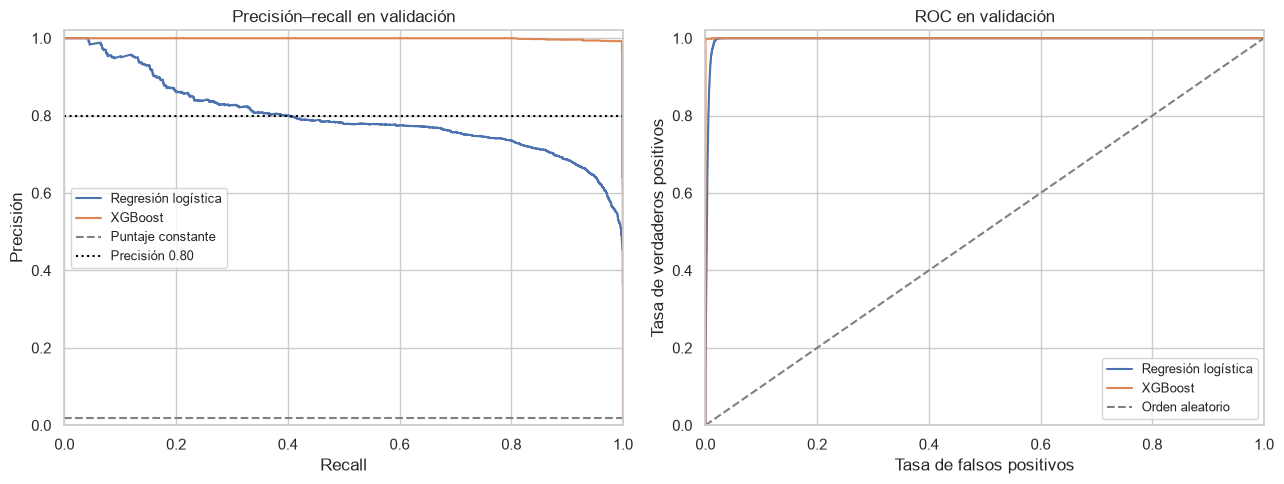

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, probabilidades in probabilidades_binarias.items():
    precision, recall, _ = precision_recall_curve(y_val_bin, probabilidades)
    fpr, tpr, _ = roc_curve(y_val_bin, probabilidades)
    ejes[0].plot(recall, precision, label=nombre)
    ejes[1].plot(fpr, tpr, label=nombre)

# Añadir referencias y límites comunes sin modificar las predicciones.
ejes[0].axhline(y_val_bin.mean(), color="gray", linestyle="--", label="Puntaje constante")
ejes[0].axhline(0.80, color="black", linestyle=":", label="Precisión 0.80")
ejes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Orden aleatorio")
ejes[0].set(title="Precisión–recall en validación", xlabel="Recall", ylabel="Precisión")
ejes[1].set(title="ROC en validación", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
for eje in ejes:
    eje.set_xlim(0, 1)
    eje.set_ylim(0, 1.02)
    eje.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 7. Evaluación multiclase

Elegiremos la clase con mayor probabilidad entre las cinco. Esta decisión es distinta de aplicar el umbral binario: ambos modelos se entrenaron por separado y sus resultados no tienen por qué coincidir fila por fila.

En las matrices, **las filas son las clases reales y las columnas las predichas**. La diagonal contiene aciertos. También mostraremos precisión, recall y F1 por clase, y F1 macro como promedio que da el mismo peso a cada clase. No usaremos accuracy como métrica principal.

Las clases provienen de la regla de primera falla y desempate del paso 04; las fallas simultáneas no quedan representadas por completo en una clase única.

,modelo,F1_macro_5_clases,F1_macro_componentes
0,Regresión logística,0.6124,0.5200
1,XGBoost,0.9946,0.9933


,clase,modelo,precision,recall,f1-score,support
0,ninguno,Regresión logística,0.9999,0.9648,0.9821,141348.0
1,comp1,Regresión logística,0.1660,0.9839,0.2841,498.0
2,comp2,Regresión logística,0.5531,0.9843,0.7082,1080.0
3,comp3,Regresión logística,0.3454,0.9859,0.5116,426.0
4,comp4,Regresión logística,0.4102,0.9660,0.5759,648.0
5,ninguno,XGBoost,1.0000,0.9998,0.9999,141348.0
6,comp1,XGBoost,0.9745,0.9960,0.9851,498.0
7,comp2,XGBoost,1.0000,1.0000,1.0000,1080.0
8,comp3,XGBoost,1.0000,0.9977,0.9988,426.0
9,comp4,XGBoost,0.9789,1.0000,0.9893,648.0


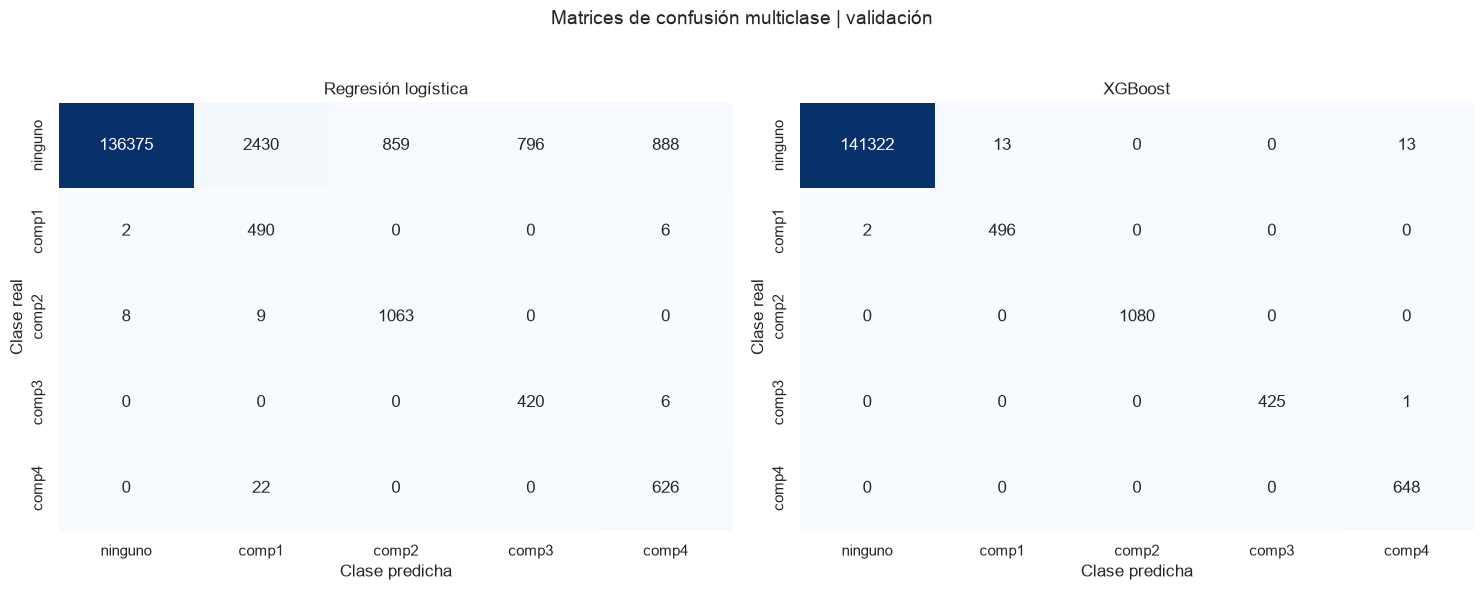

In [8]:
predicciones_multiclase = {}
metricas_multiclase = []
informes = []
fig, ejes = plt.subplots(1, 2, figsize=(15, 6))
for (nombre, probabilidades), eje in zip(probabilidades_multiclase.items(), ejes):
    assert np.isfinite(probabilidades).all()
    assert np.allclose(probabilidades.sum(axis=1), 1, atol=1e-5)
    prediccion = np.argmax(probabilidades, axis=1)
    predicciones_multiclase[nombre] = prediccion
    matriz = confusion_matrix(y_val_multi, prediccion, labels=range(5))
    assert matriz.sum() == len(y_val_multi)

    # Añadir el detalle por clase para no ocultar los componentes menos frecuentes.
    reporte = classification_report(y_val_multi, prediccion, labels=range(5),
                                    target_names=nombres_clases, output_dict=True, zero_division=0)
    detalle = pd.DataFrame(reporte).T.loc[nombres_clases, ["precision", "recall", "f1-score", "support"]]
    detalle.insert(0, "modelo", nombre)
    detalle.index.name = "clase"
    informes.append(detalle.reset_index())
    metricas_multiclase.append({"modelo": nombre,
        "F1_macro_5_clases": f1_score(y_val_multi, prediccion, labels=range(5), average="macro", zero_division=0),
        "F1_macro_componentes": f1_score(y_val_multi, prediccion, labels=[1, 2, 3, 4], average="macro", zero_division=0)})

    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=nombres_clases, yticklabels=nombres_clases, ax=eje)
    eje.set_title(nombre)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")

metricas_multiclase = pd.DataFrame(metricas_multiclase)
informes_multiclase = pd.concat(informes, ignore_index=True)
display(metricas_multiclase.round(4))
display(informes_multiclase.round(4))
fig.suptitle("Matrices de confusión multiclase | validación", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

El **F1 macro de las cinco clases** fue **0.6124 para regresión logística** y **0.9946 para XGBoost**. Si promediamos solo los cuatro componentes, fue **0.5200 y 0.9933**, respectivamente. Así evitamos que el buen resultado de `ninguno` oculte el comportamiento de los componentes.

La regresión logística detecta gran parte de las horas positivas de cada componente, pero confunde **4,973 horas realmente sin falla con algún componente**. Esto explica sus precisiones más bajas por componente, especialmente en comp1. La ponderación de clases favorece atender a las fallas, pero también puede aumentar falsas alertas.

XGBoost confunde **26 horas sin falla con un componente**. En sus filas de fallas, comp1 tiene dos horas predichas como `ninguno`, y comp3 una predicha como comp4. Estas son confusiones por hora y bajo la regla de clase única del paso 04, no un conteo de fallas físicas perdidas o reparaciones necesarias.

**En esta primera comparación de validación, XGBoost supera a la regresión logística en ambas tareas.** No se ha evaluado prueba, calculado anticipación por evento ni demostrado beneficio económico.

## 8. Comprobar el tratamiento de los faltantes

Verificaremos que la imputación aprendió las medianas de entrenamiento y que las entradas transformadas no conservan vacíos. No se modifica el pipeline de preparación del paso 04 ni sus CSV. Las tablas y figuras anteriores permanecen como salidas del notebook; al volver a ejecutarlo, se regeneran aquí.

In [9]:
# Comparar las medianas aprendidas con las calculadas directamente en entrenamiento.
medianas_esperadas = X_train[columnas_numericas].median().to_numpy()
for familia in [modelos_binarios, modelos_multiclase]:
    for pipeline in familia.values():
        transformador = pipeline.named_steps["preparar"]
        imputador = transformador.named_transformers_["numericas"].named_steps["imputar"]
        assert np.allclose(imputador.statistics_, medianas_esperadas)

        # Transformar una muestra que incluye las horas iniciales con faltantes.
        muestra_transformada = transformador.transform(X_train.head(100))
        assert np.isfinite(muestra_transformada).all()

print("Las medianas se aprendieron con entrenamiento y las entradas transformadas no contienen faltantes.")

Las medianas se aprendieron con entrenamiento y las entradas transformadas no contienen faltantes.


## 9. Cierre y reproducibilidad

Para repetir esta comparación, primero generar los conjuntos con el notebook 04 o con:

```bash
python Preprocesamiento/preparar_datos.py
```

Después ejecutar todas las celdas de este notebook en orden. La comparación usa todos los registros de entrenamiento, parámetros declarados y semilla 42. No hay búsqueda de hiperparámetros ni selección por prueba. Las versiones del entorno están en `requirements.txt`.

Las métricas, figuras y verificaciones se regeneran dentro de este mismo notebook, sin guardar CSV, imágenes ni modelos por separado. Los tiempos pueden cambiar entre equipos y puede haber pequeñas diferencias numéricas entre plataformas.

Las métricas aquí son **por hora** y sobre datos simulados. No representan todavía fallas evitadas, alertas sostenidas, anticipación por evento ni ahorro económico. Esas evaluaciones corresponden a pasos posteriores.
